# Chapitre 3 - Exercices 3.21 à 3.25

| Exercice | Thème |
|---|---|
| 3.21 | Régression de rang réduit et corrélations canoniques |
| 3.22 | Invariance de la régression de rang réduit au choix de $\Sigma$ |
| 3.23 | Corrélations liées et décroissantes le long du chemin LAR |
| 3.24 | La direction LAR fait des angles égaux avec les variables actives |
| 3.25 | « Look-ahead » du LAR : quelle variable entre, et quand |

Les fonctions utilisées (CCA, régression de rang réduit, LAR…) sont dans
`esl/ch03_regression_complements.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch03_regression_complements as rc

set_style()
np.set_printoptions(precision=4, suppress=True)

## Exercice 3.21 : Régression de rang réduit

**Contexte (section 3.7).** On observe $K$ réponses : $\mathbf Y$ est $N\times K$, $\mathbf X$
est $N\times p$ (de rang $p$), les deux centrées. La **régression de rang réduit** cherche
une matrice de coefficients $\mathbf B$ ($p\times K$) de rang $m$ imposé :

$$
\hat{\mathbf B}^{rr}(m) = \operatorname*{argmin}_{\operatorname{rang}(\mathbf B)=m}\ \sum_{i=1}^N(y_i-\mathbf B^Tx_i)^T\Sigma^{-1}(y_i-\mathbf B^Tx_i)
\qquad\text{(éq. (3.68))}
$$

où $y_i, x_i$ sont les lignes de $\mathbf Y,\mathbf X$ (écrites en colonnes) et $\Sigma$ la
covariance des erreurs.

**Énoncé (reformulé).** Montrer que si $\Sigma$ est estimée par $\mathbf Y^T\mathbf Y/N$, la
solution est $\hat{\mathbf B}^{rr}(m) = \hat{\mathbf B}\,\mathbf U_m\mathbf U_m^-$ (éq. (3.69)),
où $\hat{\mathbf B}=(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf Y$ est l'estimateur des moindres
carrés, $\mathbf U_m$ la matrice $K\times m$ des $m$ premiers vecteurs canoniques côté
réponses, et $\mathbf U_m^-$ un inverse généralisé. *Indication :* poser
$\mathbf Y^*=\mathbf Y\Sigma^{-1/2}$, travailler avec les vecteurs canoniques $\mathbf u_m^*$,
et montrer que $\mathbf U_m=\Sigma^{-1/2}\mathbf U_m^*$ et
$\mathbf U_m^-=\mathbf U_m^{*T}\Sigma^{1/2}$.

### Rappels : trace et norme de Frobenius

Pour une matrice $\mathbf A$ ($N\times K$), la **norme de Frobenius** est
$\|\mathbf A\|_F^2=\sum_{i,k}a_{ik}^2=\operatorname{tr}(\mathbf A^T\mathbf A)=\operatorname{tr}(\mathbf A\mathbf A^T)$.
On utilisera :

- la trace est linéaire et $\operatorname{tr}(\mathbf A\mathbf B)=\operatorname{tr}(\mathbf B\mathbf A)$ ;
- $\|\mathbf A+\mathbf C\|_F^2=\|\mathbf A\|_F^2+2\operatorname{tr}(\mathbf A^T\mathbf C)+\|\mathbf C\|_F^2$
  (Pythagore si $\operatorname{tr}(\mathbf A^T\mathbf C)=0$) ;
- pour un vecteur $z$ et une matrice symétrique $\mathbf S$, $z^T\mathbf Sz=\operatorname{tr}(\mathbf S zz^T)$.

### Rappel : meilleure approximation de rang $m$ (Eckart–Young)

**Théorème.** Soit $\mathbf M$ ($N\times K$) et $\mathbf S=\mathbf M^T\mathbf M=\sum_j\mu_j\mathbf e_j\mathbf e_j^T$
sa décomposition spectrale ($\mu_1\ge\dots\ge\mu_K\ge0$, $\mathbf e_j$ orthonormés : ce sont les
vecteurs singuliers à droite de $\mathbf M$). Parmi les matrices $\mathbf C$ de rang $\le m$,
$\|\mathbf M-\mathbf C\|_F$ est minimale pour $\mathbf C=\mathbf M\mathbf E_m\mathbf E_m^T$, où
$\mathbf E_m=[\mathbf e_1,\dots,\mathbf e_m]$.

*Preuve.* Soit $\mathbf C$ de rang $\le m$ et $\mathbf P$ le projecteur orthogonal ($K\times K$)
sur l'espace engendré par ses lignes, de dimension $\le m$.
1. Chaque ligne de $\mathbf C$ est dans $\operatorname{Im}\mathbf P$ ; la plus proche de la ligne
   correspondante de $\mathbf M$ est sa projection. Donc $\|\mathbf M-\mathbf C\|_F^2\ge\|\mathbf M-\mathbf M\mathbf P\|_F^2=\|\mathbf M\|_F^2-\operatorname{tr}(\mathbf P\mathbf S)$ (Pythagore).
2. $\operatorname{tr}(\mathbf P\mathbf S)=\sum_j\mu_j\,\mathbf e_j^T\mathbf P\mathbf e_j=\sum_j\mu_jw_j$ avec
   $w_j=\|\mathbf P\mathbf e_j\|^2\in[0,1]$ et $\sum_jw_j=\operatorname{tr}\mathbf P\le m$.
   Une somme $\sum_j\mu_jw_j$ avec de tels poids est au plus $\mu_1+\dots+\mu_m$ (on met tout
   le poids disponible sur les plus grands $\mu_j$), valeur atteinte pour $\mathbf P=\mathbf E_m\mathbf E_m^T$.

D'où $\|\mathbf M-\mathbf C\|_F^2\ge\sum_{j>m}\mu_j=\|\mathbf M-\mathbf M\mathbf E_m\mathbf E_m^T\|_F^2$. $\square$

### Étape 1 : écriture matricielle et blanchiment

Comme $z^T\Sigma^{-1}z=\|\Sigma^{-1/2}z\|^2$, le critère (3.68) s'écrit

$$
J(\mathbf B)=\sum_i\big\|\Sigma^{-1/2}(y_i-\mathbf B^Tx_i)\big\|^2=\big\|(\mathbf Y-\mathbf X\mathbf B)\Sigma^{-1/2}\big\|_F^2 ,
$$

puisque la $i$-ième ligne de $(\mathbf Y-\mathbf X\mathbf B)\Sigma^{-1/2}$ est
$(y_i-\mathbf B^Tx_i)^T\Sigma^{-1/2}$. Avec $\mathbf Y^*=\mathbf Y\Sigma^{-1/2}$ (réponses
« blanchies ») et $\mathbf B^*=\mathbf B\Sigma^{-1/2}$ :
$J(\mathbf B)=\|\mathbf Y^*-\mathbf X\mathbf B^*\|_F^2$. Comme $\Sigma^{-1/2}$ est inversible,
$\operatorname{rang}(\mathbf B^*)=\operatorname{rang}(\mathbf B)$.

### Étape 2 : Pythagore

Soit $\hat{\mathbf B}^*=(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf Y^*=\hat{\mathbf B}\Sigma^{-1/2}$ et
$\hat{\mathbf Y}^*=\mathbf X\hat{\mathbf B}^*$. On écrit
$\mathbf Y^*-\mathbf X\mathbf B^*=(\mathbf Y^*-\hat{\mathbf Y}^*)+\mathbf X(\hat{\mathbf B}^*-\mathbf B^*)$ ;
le terme croisé $2\operatorname{tr}\big[(\mathbf Y^*-\hat{\mathbf Y}^*)^T\mathbf X(\hat{\mathbf B}^*-\mathbf B^*)\big]$
est nul car $\mathbf X^T(\mathbf Y^*-\hat{\mathbf Y}^*)=0$ (équations normales). Donc

$$
J(\mathbf B)=\underbrace{\|\mathbf Y^*-\hat{\mathbf Y}^*\|_F^2}_{\text{indépendant de }\mathbf B}+\|\hat{\mathbf Y}^*-\mathbf X\mathbf B^*\|_F^2 .
$$

Il s'agit d'approcher $\hat{\mathbf Y}^*$ par une matrice $\mathbf X\mathbf B^*$ de rang $m$
($\mathbf X$ est injective, donc $\operatorname{rang}(\mathbf X\mathbf B^*)=\operatorname{rang}(\mathbf B^*)$).

### Étape 3 : Eckart–Young

La meilleure approximation de rang $m$ de $\hat{\mathbf Y}^*$ est
$\hat{\mathbf Y}^*\mathbf E_m\mathbf E_m^T$, où les $\mathbf e_j$ sont les vecteurs propres de
$\hat{\mathbf Y}^{*T}\hat{\mathbf Y}^*$. Elle est de la forme $\mathbf X\mathbf B^*$ avec
$\mathbf B^*=\hat{\mathbf B}^*\mathbf E_m\mathbf E_m^T$ : elle est donc **atteignable**. Ainsi

$$
\hat{\mathbf B}^{rr}(m)=\hat{\mathbf B}\,\Sigma^{-1/2}\mathbf E_m\mathbf E_m^T\Sigma^{1/2}.
\qquad(\star)
$$

Cette formule vaut pour **toute** matrice $\Sigma$ symétrique définie positive.

### Étape 4 : identification avec la CCA lorsque $\Sigma=\mathbf Y^T\mathbf Y/N$

Notons $\mathbf H=\mathbf X(\mathbf X^T\mathbf X)^{-1}\mathbf X^T$. Alors
$\hat{\mathbf Y}^{*T}\hat{\mathbf Y}^*=\Sigma^{-1/2}\mathbf Y^T\mathbf H\mathbf Y\Sigma^{-1/2}$, et
comme $\Sigma^{-1/2}=\sqrt N(\mathbf Y^T\mathbf Y)^{-1/2}$,

$$
\hat{\mathbf Y}^{*T}\hat{\mathbf Y}^*=N\,(\mathbf Y^T\mathbf Y)^{-1/2}\mathbf Y^T\mathbf X(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf Y(\mathbf Y^T\mathbf Y)^{-1/2}=N\,\mathbf M\mathbf M^T,
$$

avec $\mathbf M=(\mathbf Y^T\mathbf Y)^{-1/2}\mathbf Y^T\mathbf X(\mathbf X^T\mathbf X)^{-1/2}=\mathbf U^*\mathbf D^*\mathbf V^{*T}$,
la matrice de l'éq. (3.87). Donc $\hat{\mathbf Y}^{*T}\hat{\mathbf Y}^*=N\,\mathbf U^*\mathbf D^{*2}\mathbf U^{*T}$ :
ses vecteurs propres sont les **vecteurs singuliers à gauche $\mathbf u_m^*$ de la CCA**,
rangés dans le même ordre (corrélations canoniques décroissantes). Ainsi $\mathbf E_m=\mathbf U_m^*$.

> **Remarque.** Ce sont aussi les vecteurs canoniques de la CCA entre $\mathbf Y^*$ et $\mathbf X$,
> car $\mathbf Y^{*T}\mathbf Y^*=N\mathbf I$ : c'est le sens de l'indication.

### Conclusion

En reportant dans $(\star)$ :

$$
\hat{\mathbf B}^{rr}(m)=\hat{\mathbf B}\,\underbrace{\Sigma^{-1/2}\mathbf U_m^*}_{\mathbf U_m}\ \underbrace{\mathbf U_m^{*T}\Sigma^{1/2}}_{\mathbf U_m^-}=\hat{\mathbf B}\,\mathbf U_m\mathbf U_m^- .
$$

- $\mathbf U_m=\Sigma^{-1/2}\mathbf U_m^*=\sqrt N\,(\mathbf Y^T\mathbf Y)^{-1/2}\mathbf U_m^*$ : ce sont,
  au facteur $\sqrt N$ près, les vecteurs canoniques $\mathbf u_m$ de l'exercice 3.20 (le facteur
  disparaît dans le produit $\mathbf U_m\mathbf U_m^-$).
- $\mathbf U_m^-\mathbf U_m=\mathbf U_m^{*T}\mathbf U_m^*=\mathbf I_m$ : $\mathbf U_m^-$ est bien un
  inverse (à gauche) généralisé de $\mathbf U_m$.

### Vérification numérique

Simulation : $K=4$ réponses qui dépendent de $p=6$ entrées à travers seulement **deux**
combinaisons linéaires (vrai rang 2), plus du bruit.

In [2]:
rng = np.random.RandomState(0)
N, p, K = 200, 6, 4
X = rng.randn(N, p)
B_true = rng.randn(p, 2) @ rng.randn(2, K)
Y = X @ B_true + 1.5 * rng.randn(N, K)
X -= X.mean(0)
Y -= Y.mean(0)
Sigma = Y.T @ Y / N
for m in range(1, K + 1):
    B_gen = rc.reduced_rank_regression(X, Y, m, Sigma)      # formule (*)
    B_cca = rc.reduced_rank_cca(X, Y, m)                    # formule (3.69)
    print(f"m = {m} : rang = {np.linalg.matrix_rank(B_cca)}, "
          f"écart (*) / (3.69) = {np.abs(B_gen - B_cca).max():.1e}, "
          f"critère = {rc.rrr_criterion(X, Y, B_cca, Sigma):.3f}")

m = 1 : rang = 1, écart (*) / (3.69) = 2.7e-15, critère = 610.654
m = 2 : rang = 2, écart (*) / (3.69) = 2.2e-15, critère = 542.585
m = 3 : rang = 3, écart (*) / (3.69) = 2.2e-15, critère = 540.635
m = 4 : rang = 4, écart (*) / (3.69) = 2.2e-15, critère = 540.091


Contrôle indépendant : on minimise directement le critère sur les matrices de rang $m$
écrites $\mathbf B=\mathbf G\mathbf H^T$ ($\mathbf G$ : $p\times m$, $\mathbf H$ : $K\times m$) par
un optimiseur numérique générique (BFGS), depuis plusieurs points de départ.

In [3]:
def best_numeric(m, n_starts=5):
    Sinv = np.linalg.inv(Sigma)

    def f(theta):
        G, H = theta[:p * m].reshape(p, m), theta[p * m:].reshape(K, m)
        E = Y - X @ G @ H.T
        grad_B = -2 * X.T @ E @ Sinv
        return np.sum((E @ Sinv) * E), np.r_[(grad_B @ H).ravel(), (grad_B.T @ G).ravel()]

    vals = [minimize(f, rng.randn((p + K) * m), jac=True, method="BFGS").fun for _ in range(n_starts)]
    return min(vals)


for m in (1, 2, 3):
    print(f"m = {m} : formule (3.69) = {rc.rrr_criterion(X, Y, rc.reduced_rank_cca(X, Y, m), Sigma):.5f}"
          f"   optimiseur = {best_numeric(m):.5f}")

m = 1 : formule (3.69) = 610.65389   optimiseur = 610.65389
m = 2 : formule (3.69) = 542.58488   optimiseur = 542.58488
m = 3 : formule (3.69) = 540.63530   optimiseur = 540.63530


Le critère décroît avec $m$, très fortement jusqu'au vrai rang 2, puis à peine : les
directions canoniques au-delà ne capturent que du bruit.

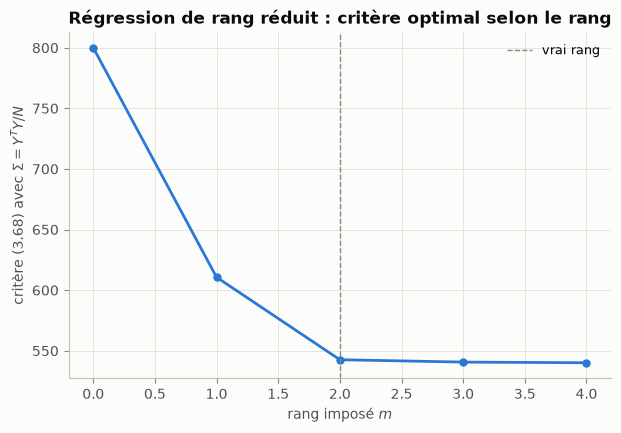

In [4]:
crit = [rc.rrr_criterion(X, Y, rc.reduced_rank_cca(X, Y, m), Sigma) for m in range(0, K + 1)]
fig, ax = plt.subplots()
ax.plot(range(K + 1), crit, "o-", color=BLUE)
ax.axvline(2, color=GRAY, ls="--", lw=1, label="vrai rang")
ax.set_xlabel("rang imposé $m$")
ax.set_ylabel(r"critère (3.68) avec $\Sigma = Y^TY/N$")
ax.set_title("Régression de rang réduit : critère optimal selon le rang")
ax.legend()
plt.show()

> **À retenir.** Après blanchiment des réponses, la régression de rang réduit est une
> **approximation de rang $m$ (Eckart–Young) des valeurs ajustées** des moindres carrés. Avec
> $\Sigma=\mathbf Y^T\mathbf Y/N$, les directions retenues sont les vecteurs canoniques de la
> CCA : $\hat{\mathbf B}^{rr}(m)=\hat{\mathbf B}\mathbf U_m\mathbf U_m^-$ régresse sur les
> réponses « mises en commun » $\mathbf Y\mathbf U_m$ puis revient dans l'espace des réponses.

## Exercice 3.22 : Le choix de $\Sigma$ ne change pas la solution

**Énoncé (reformulé).** Montrer que la solution de l'exercice 3.21 est inchangée si l'on
estime $\Sigma$ par la quantité plus naturelle
$\tilde\Sigma=(\mathbf Y-\mathbf X\hat{\mathbf B})^T(\mathbf Y-\mathbf X\hat{\mathbf B})/(N-pK)$
(covariance des résidus des moindres carrés).

### Reformulation de $(\star)$ en problème aux valeurs propres généralisé

Pour une $\Sigma$ quelconque, posons $\mathbf w_j=\Sigma^{-1/2}\mathbf e_j$ et
$\hat{\mathbf Y}=\mathbf X\hat{\mathbf B}$. La relation
$\Sigma^{-1/2}\hat{\mathbf Y}^T\hat{\mathbf Y}\Sigma^{-1/2}\mathbf e_j=\mu_j\mathbf e_j$ équivaut
(multiplier à gauche par $\Sigma^{1/2}$) à

$$
\hat{\mathbf Y}^T\hat{\mathbf Y}\,\mathbf w_j=\mu_j\,\Sigma\,\mathbf w_j,
\qquad \mathbf w_j^T\Sigma\mathbf w_\ell=\mathbf e_j^T\mathbf e_\ell=\delta_{j\ell}.
$$

Et $(\star)$ s'écrit $\hat{\mathbf B}^{rr}(m)=\hat{\mathbf B}\,\mathbf Q_m$ avec
$\mathbf Q_m=\mathbf W_m\mathbf W_m^T\Sigma$. On vérifie que $\mathbf Q_m\mathbf w_j=\mathbf W_m(\mathbf W_m^T\Sigma\mathbf w_j)$
vaut $\mathbf w_j$ si $j\le m$ et $0$ si $j>m$ : **$\mathbf Q_m$ est la projection sur
$\operatorname{Vect}(\mathbf w_1..\mathbf w_m)$ parallèlement à $\operatorname{Vect}(\mathbf w_{m+1}..\mathbf w_K)$**.
Elle ne dépend que de ces deux sous-espaces.

### Les deux choix de $\Sigma$ ont les mêmes vecteurs propres généralisés

Notons $\mathbf R=(\mathbf Y-\hat{\mathbf Y})^T(\mathbf Y-\hat{\mathbf Y})$. Comme
$\hat{\mathbf Y}^T(\mathbf Y-\hat{\mathbf Y})=0$, on a $\mathbf Y^T\mathbf Y=\hat{\mathbf Y}^T\hat{\mathbf Y}+\mathbf R$.
Les constantes $1/N$ et $1/(N-pK)$ ne changent pas les vecteurs propres (seulement leur
normalisation, qui disparaît dans $\mathbf Q_m$) ; comparons donc $\Sigma_1=\hat{\mathbf Y}^T\hat{\mathbf Y}+\mathbf R$
et $\Sigma_2=\mathbf R$ (supposée définie positive). Pour $\mu\in[0,1[$ :

$$
\hat{\mathbf Y}^T\hat{\mathbf Y}\mathbf w=\mu(\hat{\mathbf Y}^T\hat{\mathbf Y}+\mathbf R)\mathbf w
\iff(1-\mu)\hat{\mathbf Y}^T\hat{\mathbf Y}\mathbf w=\mu\mathbf R\mathbf w
\iff\hat{\mathbf Y}^T\hat{\mathbf Y}\mathbf w=\frac{\mu}{1-\mu}\,\mathbf R\mathbf w .
$$

(On a bien $\mu<1$ : $\mu=\mathbf w^T\hat{\mathbf Y}^T\hat{\mathbf Y}\mathbf w/(\mathbf w^T\hat{\mathbf Y}^T\hat{\mathbf Y}\mathbf w+\mathbf w^T\mathbf R\mathbf w)$.)
Les vecteurs propres sont **les mêmes**, et comme $\mu\mapsto\mu/(1-\mu)$ est strictement
croissante, ils sont rangés **dans le même ordre**. Les sous-espaces
$\operatorname{Vect}(\mathbf w_1..\mathbf w_m)$ et $\operatorname{Vect}(\mathbf w_{m+1}..\mathbf w_K)$ sont
donc identiques, ainsi que $\mathbf Q_m$ et $\hat{\mathbf B}^{rr}(m)$. $\square$

> **Remarque.** Au passage : $\mu_j=c_j^2$ (carré de la corrélation canonique) pour $\Sigma_1$,
> et $c_j^2/(1-c_j^2)$ pour $\Sigma_2$.

### Vérification numérique

In [5]:
B_ls = np.linalg.lstsq(X, Y, rcond=None)[0]
E = Y - X @ B_ls
Sigma_tilde = E.T @ E / (N - p * K)
for m in range(1, K + 1):
    B1 = rc.reduced_rank_regression(X, Y, m, Sigma)
    B2 = rc.reduced_rank_regression(X, Y, m, Sigma_tilde)
    print(f"m = {m} : écart max entre les deux solutions = {np.abs(B1 - B2).max():.1e}")

m = 1 : écart max entre les deux solutions = 4.9e-15
m = 2 : écart max entre les deux solutions = 5.6e-15
m = 3 : écart max entre les deux solutions = 5.3e-15
m = 4 : écart max entre les deux solutions = 5.3e-15


In [6]:
_, _, c = rc.cca(X, Y)
Yh = X @ B_ls
mu1 = np.sort(np.linalg.eigvals(np.linalg.solve(Y.T @ Y, Yh.T @ Yh)).real)[::-1]
mu2 = np.sort(np.linalg.eigvals(np.linalg.solve(E.T @ E, Yh.T @ Yh)).real)[::-1]
print("valeurs propres avec Sigma_1 :", mu1, "  c^2 =", c ** 2)
print("valeurs propres avec Sigma_2 :", mu2, "  c^2/(1-c^2) =", c ** 2 / (1 - c ** 2))

valeurs propres avec Sigma_1 : [0.9467 0.3403 0.0097 0.0027]   c^2 = [0.9467 0.3403 0.0097 0.0027]
valeurs propres avec Sigma_2 : [17.7725  0.5159  0.0098  0.0027]   c^2/(1-c^2) = [17.7725  0.5159  0.0098  0.0027]


> **À retenir.** La régression de rang réduit ne dépend de $\Sigma$ qu'à travers les
> **directions** propres généralisées de $(\hat{\mathbf Y}^T\hat{\mathbf Y},\Sigma)$. Remplacer
> $\mathbf Y^T\mathbf Y$ par la covariance résiduelle $\mathbf Y^T\mathbf Y-\hat{\mathbf Y}^T\hat{\mathbf Y}$
> transforme les valeurs propres par une fonction croissante sans toucher aux directions.

## Exercice 3.23 : Corrélations liées le long du chemin vers les moindres carrés

**Énoncé (reformulé).** Variables et réponse sont centrées et de variance 1, et chaque
variable a la même corrélation absolue avec la réponse :
$\frac1N|\langle\mathbf x_j,\mathbf y\rangle|=\lambda$ pour $j=1,\dots,p$. Soit $\hat\beta$ les
moindres carrés et $\mathbf u(\alpha)=\alpha\mathbf X\hat\beta$, $\alpha\in[0,1]$, le vecteur
qui avance d'une fraction $\alpha$ vers l'ajustement des moindres carrés. Soit RSS la somme
des carrés résiduelle de l'ajustement complet.

(a) Montrer que $\frac1N|\langle\mathbf x_j,\mathbf y-\mathbf u(\alpha)\rangle|=(1-\alpha)\lambda$ pour tout $j$.

(b) Montrer que les corrélations entre les $\mathbf x_j$ et le résidu valent toutes
$\lambda(\alpha)=\dfrac{(1-\alpha)}{\sqrt{(1-\alpha)^2+\frac{\alpha(2-\alpha)}N\,\mathrm{RSS}}}\,\lambda$,
et décroissent donc de façon monotone vers $0$.

(c) En déduire que le LAR (section 3.4.4) garde les corrélations liées et décroissantes,
comme annoncé autour de l'éq. (3.55).

### (a) Produits scalaires avec le résidu

Par linéarité du produit scalaire,
$\langle\mathbf x_j,\mathbf y-\mathbf u(\alpha)\rangle=\langle\mathbf x_j,\mathbf y\rangle-\alpha\langle\mathbf x_j,\mathbf X\hat\beta\rangle$.
Les équations normales $\mathbf X^T(\mathbf y-\mathbf X\hat\beta)=0$ donnent
$\langle\mathbf x_j,\mathbf X\hat\beta\rangle=\langle\mathbf x_j,\mathbf y\rangle$. Donc

$$
\langle\mathbf x_j,\mathbf y-\mathbf u(\alpha)\rangle=(1-\alpha)\langle\mathbf x_j,\mathbf y\rangle
\quad\Longrightarrow\quad\tfrac1N|\langle\mathbf x_j,\mathbf y-\mathbf u(\alpha)\rangle|=(1-\alpha)\lambda .
$$

Les produits scalaires restent **égaux en valeur absolue** (et gardent leur signe).

### (b) Normalisation par l'écart-type du résidu

Le résidu $\mathbf y-\mathbf u(\alpha)$ est centré (combinaison de vecteurs centrés). Les $\mathbf x_j$
étant de variance 1, $\operatorname{Corr}(\mathbf x_j,\mathbf y-\mathbf u(\alpha))=\frac{\langle\mathbf x_j,\mathbf y-\mathbf u(\alpha)\rangle/N}{\sqrt{\|\mathbf y-\mathbf u(\alpha)\|^2/N}}$.
Calculons le dénominateur en décomposant
$\mathbf y-\mathbf u(\alpha)=(\mathbf y-\mathbf X\hat\beta)+(1-\alpha)\mathbf X\hat\beta$, somme de
deux vecteurs orthogonaux (le résidu des moindres carrés est orthogonal à $\operatorname{Im}\mathbf X$) :

$$
\|\mathbf y-\mathbf u(\alpha)\|^2=\mathrm{RSS}+(1-\alpha)^2\|\mathbf X\hat\beta\|^2
=\mathrm{RSS}+(1-\alpha)^2(N-\mathrm{RSS}),
$$

car, par Pythagore encore, $\|\mathbf X\hat\beta\|^2=\|\mathbf y\|^2-\mathrm{RSS}=N-\mathrm{RSS}$
($\mathbf y$ de variance 1). En divisant par $N$ et en regroupant :
$\frac1N\|\mathbf y-\mathbf u(\alpha)\|^2=(1-\alpha)^2+\big(1-(1-\alpha)^2\big)\frac{\mathrm{RSS}}N=(1-\alpha)^2+\frac{\alpha(2-\alpha)}N\mathrm{RSS}$.
D'où la formule annoncée pour $\lambda(\alpha)$ (en valeur absolue).

**Monotonie.** Pour $\alpha<1$, on divise numérateur et dénominateur par $1-\alpha$ :

$$
\frac{\lambda(\alpha)}{\lambda}=\Big(1+\frac{\alpha(2-\alpha)}{(1-\alpha)^2}\,\frac{\mathrm{RSS}}N\Big)^{-1/2},
\qquad \frac{\alpha(2-\alpha)}{(1-\alpha)^2}=\frac1{(1-\alpha)^2}-1 ,
$$

qui est croissante sur $[0,1[$. Donc $\lambda(\alpha)$ décroît strictement (si RSS $>0$),
de $\lambda(0)=\lambda$ à $\lambda(1)=0$.

### (c) Application au LAR

Au début de l'étape $k$ du LAR, les variables actives $\mathcal A_k$ ont toutes la même
corrélation absolue avec le résidu courant $\mathbf r_k$. La direction (3.55),
$\delta_k=(\mathbf X_{\mathcal A_k}^T\mathbf X_{\mathcal A_k})^{-1}\mathbf X_{\mathcal A_k}^T\mathbf r_k$,
est le coefficient des moindres carrés de $\mathbf r_k$ sur $\mathbf X_{\mathcal A_k}$, et le
résidu évolue en $\mathbf r_k-\alpha\mathbf X_{\mathcal A_k}\delta_k$. C'est exactement la
situation de (a)–(b) avec $\mathbf X_{\mathcal A_k}$ à la place de $\mathbf X$ et $\mathbf r_k$ à la
place de $\mathbf y$ (aucune hypothèse de variance 1 sur $\mathbf r_k$ n'est nécessaire pour (a) ;
pour (b) on remplace $N$ par $\|\mathbf r_k\|^2$). Donc, sur tout le segment de l'étape $k$, les
corrélations des variables actives restent **liées** et **décroissent** ; le pas s'arrête
quand une variable inactive les rejoint (exercice 3.25).

### Vérification numérique de (a) et (b)

On fabrique des données vérifiant l'hypothèse : $\mathbf y=\mathbf X(\mathbf X^T\mathbf X)^{-1}\mathbf s\cdot c+\mathbf e$
avec $\mathbf s\in\{\pm1\}^p$ et $\mathbf e$ orthogonal à $\mathbf 1$ et aux $\mathbf x_j$ ; alors
$\mathbf X^T\mathbf y=c\,\mathbf s$ et toutes les corrélations sont égales en valeur absolue.
On règle les normes pour que $\mathbf y$ soit de variance 1 avec $R^2=0{,}6$.